# UMI in MuJoCo - Phase 1: Environment setup

Set **Runtime > Change runtime type > GPU** before starting. Run the cells in order. First run takes about 8-12 minutes.

**Why a separate Python 3.9 environment?** The UMI repo pins `torch 2.1`, `numpy 1.24`, `diffusers 0.18.2`, `zarr 2.16` and others that do not install on Colab's default Python 3.13. This notebook creates a Python 3.9 virtual environment at `/content/umi_env` and runs all UMI and MuJoCo code through it (`!{PY} script.py`). Colab's own kernel is only used for notebook glue.

**Skipped on purpose (hardware-only):** `ur-rtde`, `spnav`, `v4l2py`, `pynput`, `atomics`, `fastcrc`, `PyExifTool`, `free-mujoco-py`, the old `robosuite` fork, and `ray` (only used for multi-run sweeps). We install the modern `mujoco` package instead.

**Colab resets the VM** (including `/content/umi_env`) when the session ends. Files saved on Google Drive survive; the environment does not, so re-run steps 2, 4, 5, 6 and 7 in a new session.

## 1. Check the GPU

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


**Note:** the pinned `torch 2.1.0` supports T4, L4, A100 and H100. It does not support the newest Blackwell-generation GPUs - if you get one of those, tell me and I will change the pins.

## 2. System libraries (headless OpenGL for MuJoCo camera rendering, ffmpeg)

In [2]:
%%bash
set -e
apt-get -qq update
apt-get -qq install -y libegl1 libgl1 libgl1-mesa-dri libglfw3 libosmesa6-dev patchelf ffmpeg > /dev/null
echo "system libraries installed"

system libraries installed


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


## 3. Paths and Google Drive
Drive keeps your dataset, checkpoints and sim demos between sessions. Set `USE_DRIVE = False` to skip it (everything is then lost when the VM resets).

In [3]:
USE_DRIVE = True

import os
if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT = '/content/drive/MyDrive/umi_mujoco'
else:
    ROOT = '/content/umi_mujoco'

for sub in ['data', 'checkpoints', 'sim_demos', 'logs']:
    os.makedirs(f'{ROOT}/{sub}', exist_ok=True)

REPO = '/content/universal_manipulation_interface'
ENV  = '/content/umi_env'
PY   = f'{ENV}/bin/python'

# make these visible to %%bash cells too
os.environ.update(ROOT=ROOT, REPO=REPO, ENV=ENV, PY=PY, WANDB_MODE='disabled')
print('ROOT:', ROOT)
print('REPO:', REPO)
print('PY  :', PY)

Mounted at /content/drive
ROOT: /content/drive/MyDrive/umi_mujoco
REPO: /content/universal_manipulation_interface
PY  : /content/umi_env/bin/python


## 4. Clone the repo (skipped if it is already there from Phase 0)

In [4]:
%%bash
if [ ! -d "$REPO/.git" ]; then
  git clone https://github.com/real-stanford/universal_manipulation_interface.git "$REPO"
fi
cd "$REPO" && git log -1 --format='repo at %h (%ad)'

repo at d095ba9 (Tue May 26 10:22:24 2026 -0700)


Cloning into '/content/universal_manipulation_interface'...


### 4b. Put the dataset on Drive (one-time)
If you downloaded `cup_in_the_wild.zarr.zip` in Phase 0 it is copied to Drive so later sessions do not need to re-download it.

In [5]:
import os, shutil
URL   = 'https://real.stanford.edu/umi/data/zarr_datasets/cup_in_the_wild.zarr.zip'
DATA  = f'{ROOT}/data/cup_in_the_wild.zarr.zip'
local = f'{REPO}/cup_in_the_wild.zarr.zip'

if os.path.exists(DATA):
    print('dataset already in', DATA)
elif os.path.exists(local):
    print('copying dataset to', DATA, '(one-time, can take a few minutes) ...')
    shutil.copy(local, DATA)
else:
    print('dataset not found yet. Download it with:')
    print('  !wget -c -P', os.path.dirname(DATA), URL)

os.environ['DATA'] = DATA
print(DATA, '| exists:', os.path.exists(DATA), '| %.2f GB' % (os.path.getsize(DATA) / 1e9) if os.path.exists(DATA) else '')

dataset not found yet. Download it with:
  !wget -c -P /content/drive/MyDrive/umi_mujoco/data https://real.stanford.edu/umi/data/zarr_datasets/cup_in_the_wild.zarr.zip
/content/drive/MyDrive/umi_mujoco/data/cup_in_the_wild.zarr.zip | exists: False 


## 5. Create the Python 3.9 environment

In [6]:
%%bash
set -e
pip -q install uv
uv python install 3.9
uv venv "$ENV" --python 3.9 --seed
"$PY" --version

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.9/17.9 MB 75.7 MB/s eta 0:00:00
Python 3.9.25


Installed Python 3.9.25 in 1.62s
 + cpython-3.9.25-linux-x86_64-gnu (python3.9)
Using CPython 3.9.25
Creating virtual environment with seed packages at: umi_env
 + packaging==26.3
 + pip==26.0.1
 + setuptools==82.0.1
 + wheel==0.48.0
Activate with: source umi_env/bin/activate


## 6. Install dependencies (about 5-8 minutes)
Versions follow the repo's `conda_environment.yaml`, minus hardware-only packages, plus `mujoco`. `huggingface_hub` is pinned because `diffusers 0.18.2` breaks with newer versions.

In [7]:
%%writefile /content/umi_requirements.txt
torch==2.1.0
torchvision==0.16.0
numpy==1.24.4
scipy==1.11.4
numba==0.57.1
pandas==2.1.4
opencv-python-headless==4.7.0.72
matplotlib==3.7.5
av==10.0.0
pyyaml==6.0.1
tqdm==4.65.0
zarr==2.16.1
numcodecs==0.11.0
hydra-core==1.2.0
wandb==0.15.8
dill==0.3.7
einops==0.6.1
diffusers==0.18.2
huggingface_hub==0.19.4
scikit-video==1.1.11
lmdb
timm==0.9.7
scikit-fda==0.9
cython==0.29.37
accelerate==0.24.1
boto3
aiohttp==3.9.5
aiofiles==23.2.1
threadpoolctl==3.2.0
imagecodecs==2023.9.18
h5py
psutil
termcolor
tensorboardX
imageio
imageio-ffmpeg
mujoco

Writing /content/umi_requirements.txt


In [10]:
%%bash
sed -i 's/^mujoco.*/mujoco==3.2.3/' /content/umi_requirements.txt
echo "requirements now say:"; grep -E '^(av|mujoco)' /content/umi_requirements.txt
set -eo pipefail
uv pip install --python "$PY" -r /content/umi_requirements.txt 2>&1 | tail -30
echo "core install finished"

requirements now say:
av==12.3.0
mujoco==3.2.3
 + regex==2026.1.15
 + requests==2.32.5
 + s3transfer==0.16.1
 + safetensors==0.7.0
 + scikit-datasets==0.2.4
 + scikit-fda==0.9
 + scikit-learn==1.6.1
 + scikit-video==1.1.11
 + scipy==1.11.4
 + sentry-sdk==2.71.0
 + setproctitle==1.3.8
 + six==1.17.0
 + smmap==5.0.3
 + sympy==1.14.0
 + tensorboardx==2.6.5
 + termcolor==3.1.0
 + threadpoolctl==3.2.0
 + timm==0.9.7
 + torch==2.1.0
 + torchvision==0.16.0
 + tqdm==4.65.0
 + triton==2.1.0
 + typing-extensions==4.16.0
 + tzdata==2026.5
 + urllib3==1.26.20
 + wandb==0.15.8
 + xarray==2024.7.0
 + yarl==1.22.0
 + zarr==2.16.1
 + zipp==3.23.1
core install finished


### 6b. robomimic and gym
`robomimic` is imported by UMI's image encoder (`CropRandomizer`). It is installed without its own dependencies, which would pull in `egl_probe` and `robosuite`. `gym 0.21.0` needs old build tools, and is allowed to fail because training normally does not need it.

In [11]:
%%bash
uv pip install --python "$PY" --no-deps robomimic==0.2.0
"$PY" -m pip -q install "pip==23.3.2" "setuptools<66" "wheel<0.40"
"$PY" -m pip -q install --no-build-isolation gym==0.21.0 || echo ">> gym install failed (usually fine, continue)"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 38.9 MB/s eta 0:00:00


Using Python 3.9.25 environment at: umi_env
Resolved 1 package in 208ms
Prepared 1 package in 1.23s
Installed 1 package in 1ms
 + robomimic==0.2.0


## 7. Verify: PyTorch, GPU and library versions

In [12]:
%%bash
"$PY" - <<'EOF'
import sys, torch, numpy, zarr, numcodecs, imagecodecs, diffusers, timm, mujoco
print('python', sys.version.split()[0])
print('torch', torch.__version__, '| cuda build', torch.version.cuda, '| gpu available', torch.cuda.is_available())
if torch.cuda.is_available():
    print('gpu', torch.cuda.get_device_name(0), '| capability', torch.cuda.get_device_capability(0))
    x = torch.randn(1024, 1024, device='cuda')
    print('gpu matmul ok:', bool(torch.isfinite(x @ x).all().item()))
else:
    print('WARNING: no GPU visible to torch (check Runtime > Change runtime type)')
print('numpy', numpy.__version__, '| zarr', zarr.__version__, '| numcodecs', numcodecs.__version__)
print('imagecodecs', imagecodecs.__version__, '| jpegxl available:', imagecodecs.JPEGXL.available)
print('diffusers', diffusers.__version__, '| timm', timm.__version__, '| mujoco', mujoco.__version__)
EOF

python 3.9.25
torch 2.1.0+cu121 | cuda build 12.1 | gpu available True
gpu Tesla T4 | capability (7, 5)
gpu matmul ok: True
numpy 1.24.4 | zarr 2.16.1 | numcodecs 0.11.0
imagecodecs 2023.9.18 | jpegxl available: True
diffusers 0.18.2 | timm 0.9.7 | mujoco 3.2.3


Expected: `gpu available True`, `numpy 1.24.4`, `zarr 2.16.1`, `jpegxl available: True`. If `jpegxl` is `False`, tell me.

## 8. Verify: every UMI module imports
This walks the `umi` and `diffusion_policy` packages and tries to import each module. Hardware-only modules are skipped or counted separately. Anything under **UNEXPECTED** is a real problem - paste it to me.

In [13]:
%%bash
cd "$REPO"
export PYTHONPATH="$REPO"
"$PY" - <<'EOF'
import importlib, pkgutil
SKIP = ('real_world', 'env_runner', 'scripts')
HARDWARE = ('v4l2py', 'spnav', 'rtde', 'pynput', 'atomics', 'fastcrc', 'exiftool', 'robosuite', 'mujoco_py')
ok, expected, bad = [], [], []
for top in ('umi', 'diffusion_policy'):
    pkg = importlib.import_module(top)
    for m in pkgutil.walk_packages(pkg.__path__, top + '.', onerror=lambda n: None):
        name = m.name
        if any(s in name for s in SKIP):
            continue
        try:
            importlib.import_module(name)
            ok.append(name)
        except Exception as e:
            first = (str(e).splitlines() or [''])[0][:110]
            msg = type(e).__name__ + ': ' + first
            (expected if any(h in msg for h in HARDWARE) else bad).append((name, msg))
print('imported OK:', len(ok), 'modules')
print('failed only because of hardware/legacy packages (safe to ignore):', len(expected))
for n, msg in expected[:8]:
    print('   ', n, '->', msg)
print('UNEXPECTED failures:', len(bad))
for n, msg in bad:
    print('   ', n, '->', msg)
if bad:
    print('\nPaste the UNEXPECTED lines to Claude - these are the ones that matter.')
EOF

imported OK: 0 modules
failed only because of hardware/legacy packages (safe to ignore): 0
UNEXPECTED failures: 0


## 9. Verify: the training config resolves
Prints the UMI diffusion-policy config (no training). Check that `shape_meta` and `task.dataset_path` appear.

In [14]:
%%bash
cd "$REPO"
export PYTHONPATH="$REPO"
"$PY" train.py --config-name=train_diffusion_unet_timm_umi_workspace --cfg job 2>&1 | head -150

name: train_diffusion_unet_timm
_target_: diffusion_policy.workspace.train_diffusion_unet_image_workspace.TrainDiffusionUnetImageWorkspace
task_name: ${task.name}
shape_meta: ${task.shape_meta}
exp_name: default
n_action_steps: 8
policy:
  _target_: diffusion_policy.policy.diffusion_unet_timm_policy.DiffusionUnetTimmPolicy
  shape_meta: ${shape_meta}
  noise_scheduler:
    _target_: diffusers.DDIMScheduler
    num_train_timesteps: 50
    beta_start: 0.0001
    beta_end: 0.02
    beta_schedule: squaredcos_cap_v2
    clip_sample: true
    set_alpha_to_one: true
    steps_offset: 0
    prediction_type: epsilon
  obs_encoder:
    _target_: diffusion_policy.model.vision.timm_obs_encoder.TimmObsEncoder
    shape_meta: ${shape_meta}
    model_name: vit_base_patch16_clip_224.openai
    pretrained: true
    frozen: false
    global_pool: ''
    feature_aggregation: attention_pool_2d
    position_encording: sinusoidal
    downsample_ratio: 32
    transforms:
    - type: RandomCrop
      ratio: 0

## 10. Verify: MuJoCo offscreen rendering
Your simulated wrist camera will render exactly like this. It tries `egl` (GPU) first, then `osmesa` (CPU, slower but always works). Note which one prints a shape and use that backend in later phases.

In [15]:
%%writefile /content/mujoco_render_test.py
import sys, numpy as np, mujoco, imageio

XML = '''
<mujoco>
  <visual><global offwidth="640" offheight="480"/></visual>
  <worldbody>
    <light pos="0 0 3" dir="0 0 -1"/>
    <geom name="table" type="plane" size="1 1 0.1" rgba="0.8 0.8 0.8 1"/>
    <body name="cube" pos="0 0 0.05">
      <freejoint/>
      <geom type="box" size="0.05 0.05 0.05" rgba="0.9 0.2 0.2 1"/>
    </body>
    <camera name="wrist" pos="0 -0.5 0.35" xyaxes="1 0 0 0 0.55 0.85" fovy="100"/>
  </worldbody>
</mujoco>
'''
model = mujoco.MjModel.from_xml_string(XML)
data = mujoco.MjData(model)
for _ in range(50):
    mujoco.mj_step(model, data)
renderer = mujoco.Renderer(model, height=224, width=224)
renderer.update_scene(data, camera='wrist')
img = renderer.render()
imageio.imwrite('/content/mujoco_test.png', img)
print('rendered', img.shape, img.dtype, '| pixel std = %.1f' % img.std())
sys.exit(0 if img.std() > 5 else 1)

Writing /content/mujoco_render_test.py


In [16]:
%%bash
for GL in egl osmesa; do
  echo "== MUJOCO_GL=$GL =="
  MUJOCO_GL=$GL PYOPENGL_PLATFORM=$GL "$PY" /content/mujoco_render_test.py 2>&1 | tail -4
  if [ "${PIPESTATUS[0]}" = "0" ]; then echo ">> $GL works"; fi
done

== MUJOCO_GL=egl ==
  File "/content/umi_env/lib/python3.9/site-packages/mujoco/egl/__init__.py", line 131, in __del__
  File "/content/umi_env/lib/python3.9/site-packages/mujoco/egl/__init__.py", line 126, in free
  File "/content/umi_env/lib/python3.9/site-packages/OpenGL/error.py", line 230, in glCheckError
OpenGL.raw.EGL._errors.EGLError: <exception str() failed>
>> egl works
== MUJOCO_GL=osmesa ==
rendered (224, 224, 3) uint8 | pixel std = 94.0
>> osmesa works


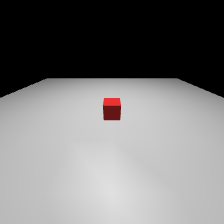

In [17]:
from IPython.display import Image, display
display(Image('/content/mujoco_test.png'))

## Phase 1 checklist

- [ ] Step 7: GPU visible, versions as expected
- [ ] Step 8: **UNEXPECTED failures: 0** (or pasted to Claude)
- [ ] Step 9: config printed, shows `shape_meta`
- [ ] Step 10: a red cube image appears; note the working GL backend (`egl` or `osmesa`)
- [ ] Dataset on Drive (step 4b)

**For the next phases:** run scripts with `!{PY} your_script.py` (set `MUJOCO_GL=egl` or `osmesa` as found above) and add `PYTHONPATH=$REPO` when importing UMI code.

Next: Phase 2 (MuJoCo scene: arm, gripper, table, objects, wrist camera).